In [1]:
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from datetime import datetime, date

In [2]:
ds = xr.load_dataset("u10_60N_50_87.grib", engine="cfgrib")
var_daily1 = ds.u.groupby(ds.u.time.dt.date).mean()

In [3]:
ds = xr.load_dataset("u10_60N_88_25.grib", engine="cfgrib")
var_daily2 = ds.u.groupby(ds.u.time.dt.date).mean()

In [4]:
var_daily = xr.concat([var_daily1, var_daily2], dim='date')
var_daily = var_daily.reset_coords(['number', 'step', 'isobaricInhPa'], drop=True)

In [5]:
dates = var_daily.date.data
datetimes = np.zeros_like(dates)
for i in range(len(dates)):
    datetimes[i] = datetime.combine(dates[i], datetime.min.time())

In [6]:
var_daily.coords["time"] = ("date", datetimes)
var_daily = var_daily.swap_dims({"date": "time"})
var_daily = var_daily.reset_coords('date', drop=True)

In [7]:
var_daily = var_daily.sel(time=slice("1950-07", "2025-06"))
var_daily = var_daily.assign_coords({'month_day': 31*var_daily['time.month'] + var_daily['time.day']})

In [8]:
weights = np.cos(np.deg2rad(var_daily.latitude))
weights.name = "weights"

In [9]:
var_daily_60Nmean = var_daily.weighted(weights).mean(dim=['longitude', 'latitude'])

In [10]:
var_7dMean_60Nmean = var_daily_60Nmean.rolling(time=7, min_periods=7, center=True).mean() 
month = var_7dMean_60Nmean.time.dt.month
day = var_7dMean_60Nmean.time.dt.day
var_7dMean_60Nmean = var_7dMean_60Nmean.sel(time=~( ((month==10)&(day<4)) | ((month==2)&(day>25)) ))

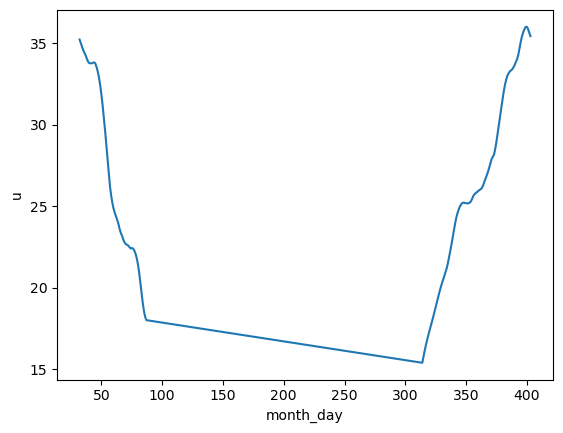

In [11]:
var_7dMean_60Nmean_train = var_7dMean_60Nmean.sel(time=slice("1950-07", "2010-06"))
var_7dMean_60Nmean_train.groupby('month_day').mean().plot()

In [12]:
var_7dMean_60Nmean_weeklyanom = var_7dMean_60Nmean.groupby('month_day') - var_7dMean_60Nmean_train.groupby('month_day').mean()

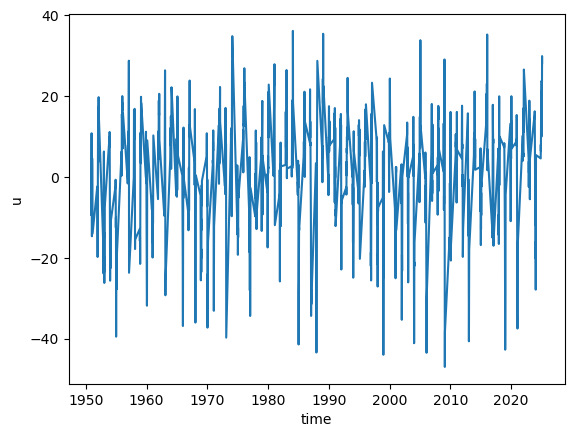

In [13]:
month = var_7dMean_60Nmean_weeklyanom.time.dt.month
day = var_7dMean_60Nmean_weeklyanom.time.dt.day
var_7dMean_60Nmean_weeklyanom_week0 = var_7dMean_60Nmean_weeklyanom.sel(time = ((month == 12) & (day >= 4)) | (month == 1) | ((month == 2) & (day <= 25)))
var_7dMean_60Nmean_weeklyanom_week1 = var_7dMean_60Nmean_weeklyanom.sel(time = ((month == 11) & (day >= 27)) | (month == 12) | (month == 1) | ((month == 2) & (day <= 18)))
var_7dMean_60Nmean_weeklyanom_week2 = var_7dMean_60Nmean_weeklyanom.sel(time = ((month == 11) & (day >= 20)) | (month == 12) | (month == 1) | ((month == 2) & (day <= 11)))
var_7dMean_60Nmean_weeklyanom_week3 = var_7dMean_60Nmean_weeklyanom.sel(time = ((month == 11) & (day >= 13)) | (month == 12) | (month == 1) | ((month == 2) & (day <= 4)))
var_7dMean_60Nmean_weeklyanom_week4 = var_7dMean_60Nmean_weeklyanom.sel(time = ((month == 11) & (day >= 6)) | (month == 12) | ((month == 1) & (day <= 28)))
var_7dMean_60Nmean_weeklyanom_week5 = var_7dMean_60Nmean_weeklyanom.sel(time = ((month == 10) & (day >= 30)) | (month == 11) | (month == 12) | ((month == 1) & (day <= 21)))
var_7dMean_60Nmean_weeklyanom_week6 = var_7dMean_60Nmean_weeklyanom.sel(time = ((month == 10) & (day >= 23)) | (month == 11) | (month == 12) | ((month == 1) & (day <= 14)))
var_7dMean_60Nmean_weeklyanom_week7 = var_7dMean_60Nmean_weeklyanom.sel(time = ((month == 10) & (day >= 16)) | (month == 11) | (month == 12) | ((month == 1) & (day <= 7)))
var_7dMean_60Nmean_weeklyanom_week3.plot()

In [14]:
df_var_week3 = var_7dMean_60Nmean_weeklyanom_week3.to_dataframe(name='u10_60N')
df_var_week3 = df_var_week3.drop(['month_day'], axis=1)
df_var_week3

,u10_60N
time,
1950-11-13,-9.403397
1950-11-14,-8.766685
1950-11-15,-8.281581
1950-11-16,-7.748720
1950-11-17,-7.080578
...,...
2025-01-31,27.604311
2025-02-01,28.859399
2025-02-02,29.853131


In [14]:
df_var_week4 = var_7dMean_60Nmean_weeklyanom_week4.to_dataframe(name='u10_60N')
df_var_week4 = df_var_week4.drop(['month_day'], axis=1)
df_var_week4

,u10_60N
time,
1950-11-06,-8.089399
1950-11-07,-8.860304
1950-11-08,-9.580262
1950-11-09,-10.153679
1950-11-10,-10.375203
...,...
2025-01-24,23.884153
2025-01-25,22.899038
2025-01-26,21.624490


In [15]:
df_var_week5 = var_7dMean_60Nmean_weeklyanom_week5.to_dataframe(name='u10_60N')
df_var_week5 = df_var_week5.drop(['month_day'], axis=1)
df_var_week5

,u10_60N
time,
1950-10-30,-2.979133
1950-10-31,-3.740913
1950-11-01,-4.345721
1950-11-02,-4.877868
1950-11-03,-5.602905
...,...
2025-01-17,11.025737
2025-01-18,12.868728
2025-01-19,15.701951


In [15]:
df_var_week6 = var_7dMean_60Nmean_weeklyanom_week6.to_dataframe(name='u10_60N')
df_var_week6 = df_var_week6.drop(['month_day'], axis=1)
df_var_week6

,u10_60N
time,
1950-10-23,-0.173509
1950-10-24,-0.466706
1950-10-25,-0.804351
1950-10-26,-1.060158
1950-10-27,-1.199978
...,...
2025-01-10,23.103323
2025-01-11,21.701613
2025-01-12,19.372674


In [16]:
df_var_week7 = var_7dMean_60Nmean_weeklyanom_week7.to_dataframe(name='u10_60N')
df_var_week7 = df_var_week7.drop(['month_day'], axis=1)
df_var_week7

,u10_60N
time,
1950-10-16,1.765491
1950-10-17,1.478752
1950-10-18,1.240856
1950-10-19,0.927130
1950-10-20,0.527018
...,...
2025-01-03,12.971642
2025-01-04,14.806410
2025-01-05,17.157857


In [14]:
df_var_week0 = var_7dMean_60Nmean_weeklyanom_week0.to_dataframe(name='u10_60N')
df_var_week0 = df_var_week0.drop(['month_day'], axis=1)
df_var_week0

,u10_60N
time,
1950-12-04,10.247400
1950-12-05,10.678450
1950-12-06,10.770412
1950-12-07,10.590142
1950-12-08,9.992587
...,...
2025-02-21,31.803465
2025-02-22,32.524497
2025-02-23,32.365211


In [15]:
df_var_week1 = var_7dMean_60Nmean_weeklyanom_week1.to_dataframe(name='u10_60N')
df_var_week1 = df_var_week1.drop(['month_day'], axis=1)
df_var_week1

,u10_60N
time,
1950-11-27,3.352951
1950-11-28,3.958195
1950-11-29,4.903212
1950-11-30,6.068700
1950-12-01,7.194480
...,...
2025-02-14,9.397480
2025-02-15,11.676381
2025-02-16,14.712617


In [16]:
df_var_week2 = var_7dMean_60Nmean_weeklyanom_week2.to_dataframe(name='u10_60N')
df_var_week2 = df_var_week2.drop(['month_day'], axis=1)
df_var_week2

,u10_60N
time,
1950-11-20,-3.632540
1950-11-21,-1.905350
1950-11-22,-0.310283
1950-11-23,0.849727
1950-11-24,1.709911
...,...
2025-02-07,21.427005
2025-02-08,19.033920
2025-02-09,16.352756


In [16]:
df_var_week3.to_csv('u10_60N_week3.csv')

In [16]:
df_var_week4.to_csv('u10_60N_week4.csv')
df_var_week5.to_csv('u10_60N_week5.csv')

In [17]:
df_var_week6.to_csv('u10_60N_week6.csv')
df_var_week7.to_csv('u10_60N_week7.csv')

In [17]:
df_var_week0.to_csv('u10_60N_week0.csv')
df_var_week1.to_csv('u10_60N_week1.csv')
df_var_week2.to_csv('u10_60N_week2.csv')